In [1]:
from itertools import product
import numpy as np
from scipy import linalg
import matplotlib.pyplot as plt
from matplotlib import cycler
import seaborn as sns
import h5py
from sklearn.decomposition import SparsePCA
from tqdm import tqdm

In [2]:
fh = h5py.File("./toy_data/ar_data", mode="r")

In [ ]:
# SVD

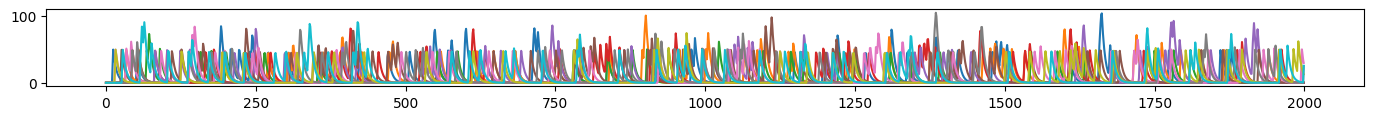

<Axes: >

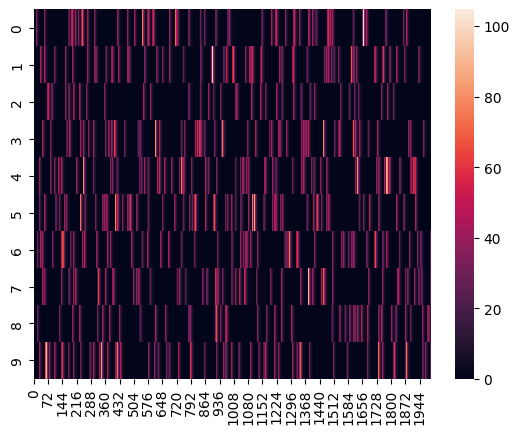

In [3]:
data = fh["clean"]

fig = plt.figure(figsize=(17, 1))
for _ in data:
    plt.plot(_)

plt.show()
sns.heatmap(data)

<Axes: >

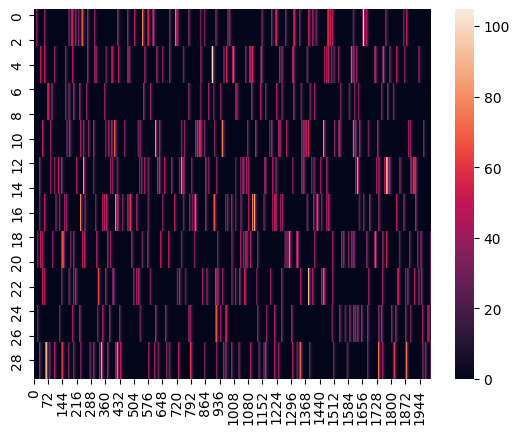

In [4]:
n_pixels = 3

clean = np.zeros((data.shape[0] * n_pixels, data.shape[1]))

for i in range(data.shape[0]):
    clean[i * n_pixels: (i * n_pixels) + n_pixels] = data[i]

sns.heatmap(clean)

100%|█████████████████████████████████████████████████████████████████████████| 15/15 [00:02<00:00,  5.20it/s]


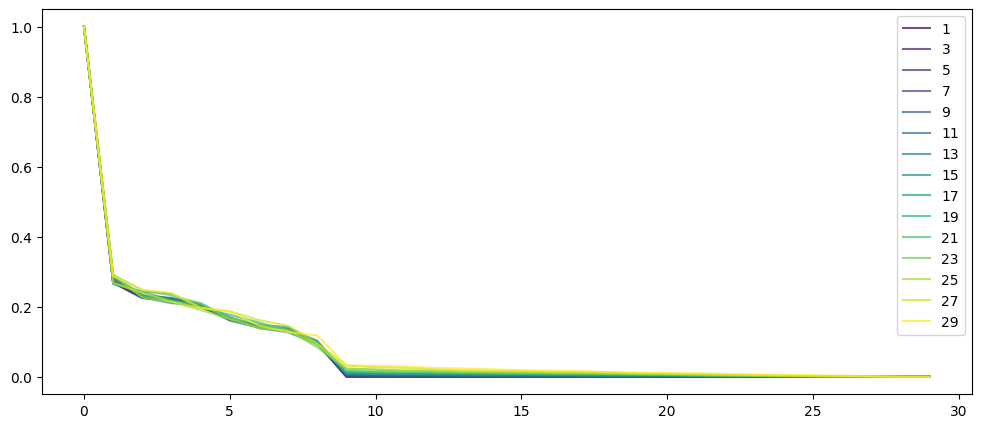

In [65]:
n_timepoints = 2_000
n_pixels = 3
n_components = 10

gaussian_noise = fh["noise"]["gaussian"]

fig = plt.figure(figsize=(12, 5))

plt.rc('axes', prop_cycle=(cycler('color', plt.cm.viridis(np.linspace(0, 1, len(gaussian_noise.keys()))))))

v_s_n = dict()
filters = dict()
P_n = dict()

for n in tqdm(sorted(map(int, gaussian_noise.keys()))):
    Y = clean[:] + gaussian_noise[str(n)][:]
    Y[-3:] = gaussian_noise[str(n)][-1]

    center = 100
    w = 6
        
    Y = linalg.hankel(Y[i, :w], Y[i, w:])

    iterator = [tuple(reversed(ixs)) for ixs in product(*[range(0, int(w / 2) * Y.shape[0], Y.shape[0])]*2)]

    Hp = np.zeros((int(w / 2)**2, Y.shape[0]**2))

    for row_ix, (block_row_ix, block_col_ix) in enumerate(iterator):
        Hp[row_ix] = H[block_row_ix:block_row_ix + Y.shape[0], block_col_ix:block_col_ix + Y.shape[0]].ravel()

    u, s, v = linalg.svd(Hp)

    u_r = u[:, 0].reshape(int(w / 2), int(w / 2))
    v_r = v[0].reshape(Y.shape[0], Y.shape[0])

    u_t, s_t, v_t = linalg.svd(u_r)

    u_s, s_s, v_s = linalg.svd(v_r)

    pca = SparsePCA(n_components=n_components, alpha=0.01, U_init=u_s, V_init=v_s)

    u_s = pca.fit_transform(v_r)
    v_s = pca.components_

    v_s_n[n] = v_s
    filters[n] = np.vstack([np.kron(v_t[0], v_s[i]) for i in range(10)])

    plt.plot(s_s / s_s.max(), alpha=0.7, label=str(n))

plt.legend()

In [66]:
# Estimate which $V_i$ corresponds to each clean component

<Axes: >

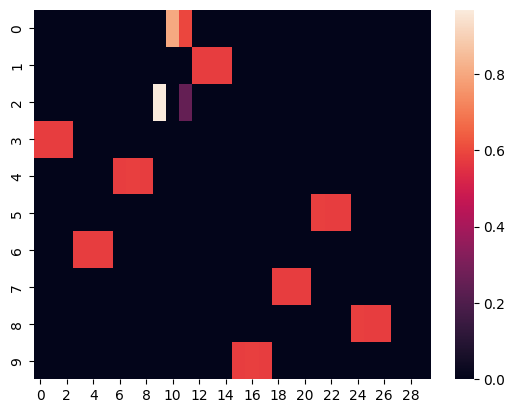

In [93]:
sns.heatmap(v_s_n[1][:10])

In [94]:
noise_ix = 1
component_ixs = list()
for i in range(0, v_s_n[noise_ix].shape[1], n_pixels):
        component_ixs.append(np.abs(v_s_n[noise_ix][:, i:i + n_pixels]).sum(axis=1).argmax())

In [95]:
component_ixs

[3, 6, 4, 0, 1, 9, 7, 5, 8, 0]

100%|████████████████████████████████████████████████████████████████████████| 15/15 [00:00<00:00, 337.61it/s]


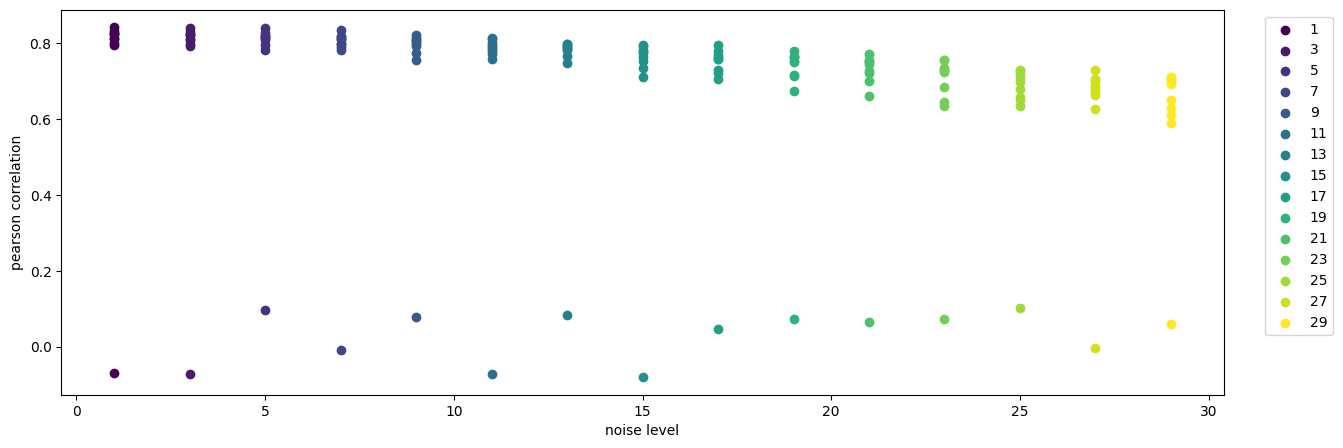

In [101]:
# pearson correlations for each noise level between each component estimate
pc = dict()

fig = plt.figure(figsize=(15, 5))
plt.rc('axes', prop_cycle=(cycler('color', plt.cm.viridis(np.linspace(0, 1, len(gaussian_noise.keys()))))))

for noise_ix in tqdm(sorted(map(int, gaussian_noise.keys()))):
    component_ixs = list()

    for i in range(0, v_s_n[noise_ix].shape[1], n_pixels):
        component_ixs.append(np.abs(v_s_n[noise_ix][:, i:i + n_pixels]).sum(axis=1).argmax())

    _pc = list()
    
    for clean_ix, estimate_ix in enumerate(component_ixs):
        x = data[clean_ix].copy()[:-n_pixels * 2]
        y = filters[noise_ix][estimate_ix] @ P_n[noise_ix]
    
        x -= x.min()
        x /= x.max()
    
        neg = np.abs(y.min())
        pos = np.abs(y.max())
    
        y *= np.sign(y.sum())
        
        y -= y.min()
        y /= y.max()
        # fig = plt.figure(figsize=(15, 5))
        # plt.plot(x)
        # plt.plot(y)
        # plt.show()
        
        _pc.append(np.corrcoef(x, y)[0, 1])
        
    pc[noise_ix] = np.vstack(_pc)

    plt.scatter(x=np.repeat(int(noise_ix), 10), y=pc[noise_ix], label=noise_ix)

plt.xlabel("noise level")
plt.ylabel("pearson correlation")

plt.legend(loc="upper right", bbox_to_anchor=(1.1, 1))
plt.show()